In [1]:
import numpy as np
import pandas as pd

from kneed import KneeLocator
from shap import TreeExplainer
import matplotlib.pyplot as plt

from utilities import explain_instance, Monte_Carlo_Splitting, Feature_Selection
from utilities import get_understandable_features, feature_importance

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, recall_score
from sklearn.preprocessing import RobustScaler, LabelEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

#Import Data
df = pd.read_csv("Understandability_Scores_Processed.csv", index_col= 0)

#Filter for only phone data
df = df[df['Dataset'] == 2]

#Import Understandability Scores
df_phone = pd.read_csv("Phone.csv")

#Drop CustomerID since it has 0 variance
df_phone.drop('customerID', axis = 1, inplace = True)

#Deal with 0 values in TotalCharges column
df_phone['TotalCharges'] = pd.to_numeric(df_phone['TotalCharges'], errors='coerce')
df_phone['TotalCharges'] = df_phone['TotalCharges'].fillna(0)

X = df_phone.drop('Churn', axis = 1)
le = LabelEncoder()
y = le.fit_transform(df_phone['Churn'])


Step 1: Monte Carlo Splitting to establish consistent accuracy across splits

Now let's apply the pipeline to the medical data

In [9]:
#Call Monte Carlo For the Medical Data
n_runs = 50

#Define Data and Hyperparameters Here
X = df_phone.drop('Churn', axis = 1)
le = LabelEncoder()
y = le.fit_transform(df_phone['Churn'])

num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [x for x in X.columns if x not in num_features]

preprocessor = ColumnTransformer(
transformers=[
    ('num', RobustScaler(), num_features),
    ('cat', OrdinalEncoder(handle_unknown='error'), cat_features) #Change this depending on dataset
],
remainder='passthrough')

acc_out, f1_out, p_out, r_out = Monte_Carlo_Splitting(X, y, 0.3, preprocessor, n_runs)
    
#Save lists to output just in case
df_out = pd.DataFrame().from_dict({'Accuracy' : acc_out, 'F1' : f1_out, 'Precision' : p_out, 'Recall' : r_out})
df_out.to_csv('Output_Monte_Carlo_Sampling_Phone.csv')

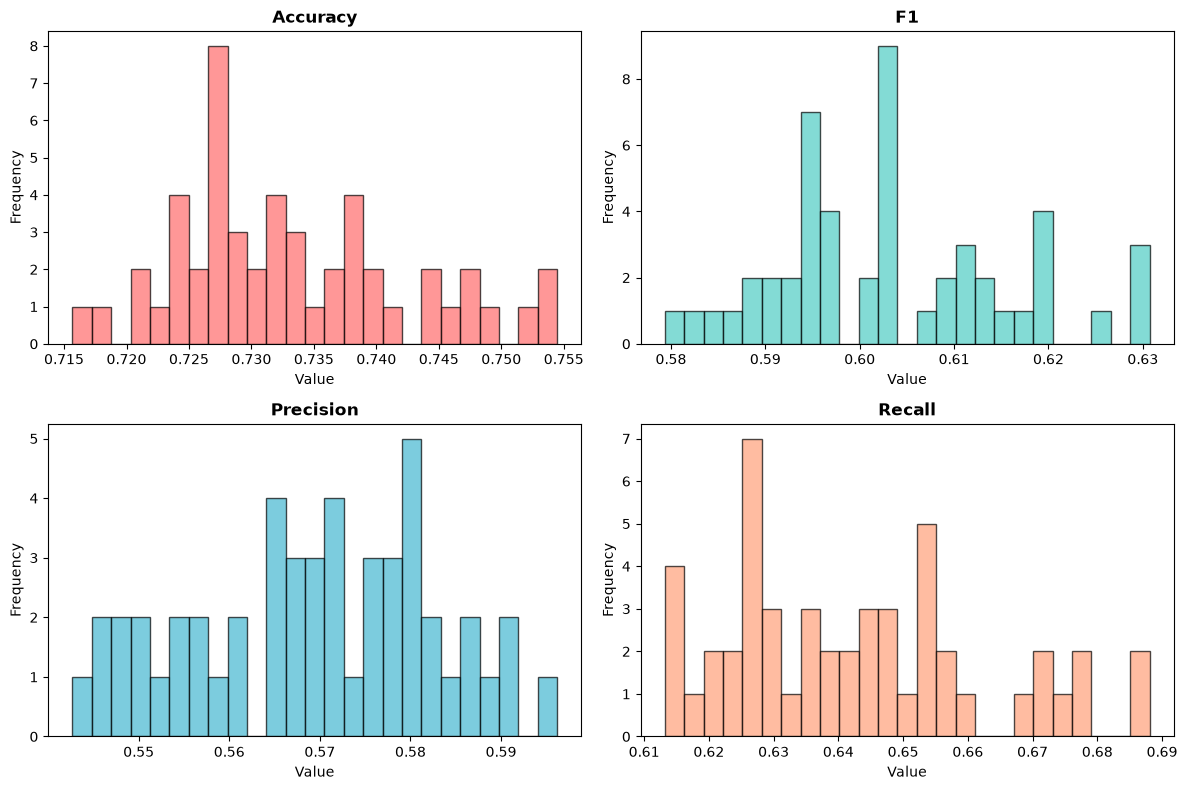

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']
columns = df_out.columns

for idx, (ax, col, color) in enumerate(zip(axs.flat, columns, colors)):
    ax.hist(df_out[col], bins=25, color=color, edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

Step 1 - done!

Step 2: Build Feature Selection mechanism.

In [2]:
def model_implementation(data, seed_n, numeric_features, categorical_features):
    """Implements the ML model and returns the performance and feature importances"""
    #Split Data
    X = data.drop('Output', axis = 1)
    y = data['Output']
    
    #Subset numerical and categorical features
    numeric_features = [x for x in numeric_features if x in data.columns.tolist()]
    categorical_features = [x for x in categorical_features if x in data.columns.tolist()]
    
    #Implement train_test_split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed_n)
    
    #Implement preprocessing
    preprocessor = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), numeric_features),
        ('cat', OrdinalEncoder(handle_unknown='error'), categorical_features)
    ],
    remainder='passthrough')
    
    #Fit preprocessing
    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)
    
    le = LabelEncoder()
    y_train = pd.Series(le.fit_transform(y_train))
    y_test = pd.Series(le.transform(y_test))
    
    #Get column names
    feature_names = preprocessor.get_feature_names_out()

    #Transform Back to df
    X_train = pd.DataFrame(X_train, columns=feature_names, index=None)
    X_test = pd.DataFrame(X_test, columns=feature_names, index=None)
    
    #Implement hyperparameter search with cross-validation
    parameters = {'max_depth' : [2, 3, 4, 5, None],
                'min_samples_split': [2, 3],
                'min_samples_leaf': [2, 3, 4],
                'criterion' : ['gini', 'entropy'],
                'class_weight' : ['balanced']}
    
    grid_search = GridSearchCV(estimator=RandomForestClassifier(random_state=seed_n), param_grid=parameters, cv=StratifiedKFold(5), scoring='balanced_accuracy', n_jobs=-1)
    
    grid_search.fit(X_train,
                    y_train)
    
    print(grid_search.best_params_)
    
    best_model = grid_search.best_estimator_
    
    best_model.fit(X_train, y_train)
    
    y_pred = best_model.predict(X_test)
    
    acc = balanced_accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    
    #Get shap values
    feature_importance_df = feature_importance(best_model, X_train, X_test, y_test, 20, preprocessor, numeric_features, categorical_features)
    
    return acc, f1, precision, recall, grid_search.best_score_, feature_importance_df, best_model, X_train, X_test, y_test, preprocessor

In Co_Op


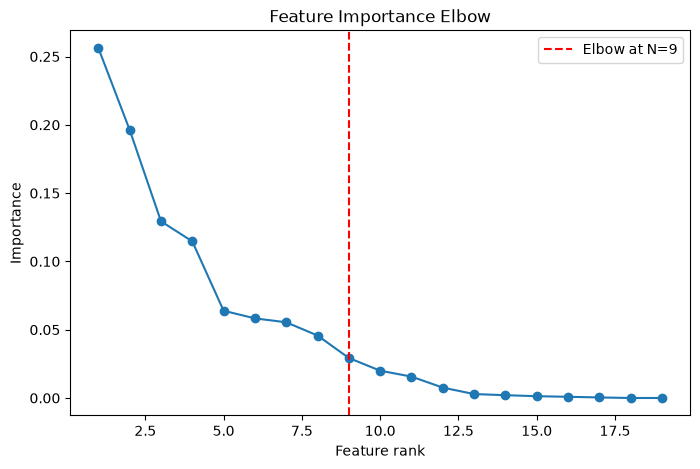

{'gender': 3.5185185185185186, 'DeviceProtection': 3.8850574712643673, 'StreamingMovies': 3.993055555555555, 'tenure': 3.515151515151515, 'TechSupport': 4.03030303030303, 'OnlineSecurity': 3.8968253968253963, 'Partner': 3.5882352941176467, 'MonthlyCharges': 4.23046875, 'SeniorCitizen': 3.571895424836601, 'OnlineBackup': 3.8296296296296295, 'TotalCharges': 4.113970588235294, 'InternetService': 3.9097222222222223, 'PhoneService': 3.8148148148148153, 'Dependents': 3.7207207207207205, 'PaymentMethod': 4.111111111111111, 'PaperlessBilling': 3.823045267489712, 'Contract': 4.522222222222222, 'StreamingTV': 4.142361111111111, 'MultipleLines': 3.6148148148148147}
{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 3, 'min_samples_split': 2}
Co-Optimised Feature Selection with five features: 
 Final CV Accuracy:  0.7632221571021808 
 Final Accuracy:  0.7524762482312513 
Final F1:  0.6111111111111112 
Final Precision:  0.492896174863388 
Final Recall:  0.80392156

In [13]:
#import data and define hyperparameters
X = df_phone.drop('Churn', axis=1)
y = df_phone['Churn']
seed = 42

#Define Preprocessor
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [x for x in X.columns if x not in num_features]

preprocessor = ColumnTransformer(
transformers=[
    ('num', RobustScaler(), num_features),
    ('cat', OrdinalEncoder(handle_unknown='error'), cat_features) #Change this depending on dataset
],
remainder='passthrough')

selected_features, n_optimal, sorted_importances, sorted_names = Feature_Selection(X, y, seed, preprocessor, True, plot=True, strictness=3)
final_features, dict_selected, df_final = get_understandable_features(selected_features, df, 5, df_phone, 'Churn')

(final_acc_coop, final_f1_coop, final_precision_coop, final_recall_coop,final_grid_acc,
importances_coop, trained_model, X_train, X_test, y_test, preprocessor) = model_implementation(
    df_final, seed, num_features, cat_features
)

print("Co-Optimised Feature Selection with five features: \n",
    "Final CV Accuracy: ", final_grid_acc, '\n',
    "Final Accuracy: ", final_acc_coop, '\n'
    "Final F1: ", final_f1_coop, '\n'
    "Final Precision: ", final_precision_coop, '\n'
    "Final Recall: ", final_recall_coop, '\n'
    "Features Selected: ", final_features, '\n')

# This IS the shap_df now — no need to call feature_importance() again
class_labels = {0: "stay with the company", 1: "change company"} #Check this

#Get DF of explanations
records = []
for x in range(20):
    records.append({
        "instance_id": x,
        "explanation": explain_instance(x, importances_coop, class_labels, top_n=5)
    })

explanation_df_coop_phone = pd.DataFrame(records)
print("Average Understandability: ", sum([dict_selected[x] for x in final_features])/5)
# explanation_df_coop_phone.to_csv('Explanations_CoOp_Phone.csv', index=False)

In [14]:
X = df_phone.drop('Churn', axis=1)
y = df_phone['Churn']
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [x for x in X.columns if x not in num_features]
seed = 42

preprocessor = ColumnTransformer(
transformers=[
    ('num', RobustScaler(), num_features),
    ('cat', OrdinalEncoder(handle_unknown='error'), cat_features)
],
remainder='passthrough')

selected_features, n_optimal, sorted_importances, sorted_names = Feature_Selection(X, y, seed, preprocessor, False, 5)
final_features, dict_selected, df_final = get_understandable_features(selected_features, df, 5, df_phone, 'Churn')

(final_acc_trad, final_f1_trad, final_precision_trad, final_recall_trad, final_grid_acc_trad,
importances_trad, trained_model_trad, X_train_trad, X_test_trad, y_test_trad, preprocessor_trad) = model_implementation(
    df_final, seed, num_features, cat_features
)

print("Traditional Feature Selection with five features: \n",
    "Final CV Accuracy: ", final_grid_acc_trad, '\n',
    "Final Accuracy: ", final_acc_trad, '\n'
    "Final F1: ", final_f1_trad, '\n'
    "Final Precision: ", final_precision_trad, '\n'
    "Final Recall: ", final_recall_trad, '\n'
    "Features Selected: ", final_features)

# This IS the shap_df now — no need to call feature_importance() again
class_labels = {0: "stay with the company", 1: "change company"}  #Make sure this is correct

#Get DF of explanations
records = []
for x in range(20):
    records.append({
        "instance_id": x,
        "explanation": explain_instance(x, importances_trad, class_labels, top_n=5)
    })

explanation_df_trad_phone = pd.DataFrame(records)
print("Average Understandability: ", sum([dict_selected[x] for x in final_features])/5)
# explanation_df_trad_phone.to_csv('Explanations_Trad_Phone.csv', index=False)

In Trad
{'gender': 3.5185185185185186, 'DeviceProtection': 3.8850574712643673, 'StreamingMovies': 3.993055555555555, 'tenure': 3.515151515151515, 'TechSupport': 4.03030303030303, 'OnlineSecurity': 3.8968253968253963, 'Partner': 3.5882352941176467, 'MonthlyCharges': 4.23046875, 'SeniorCitizen': 3.571895424836601, 'OnlineBackup': 3.8296296296296295, 'TotalCharges': 4.113970588235294, 'InternetService': 3.9097222222222223, 'PhoneService': 3.8148148148148153, 'Dependents': 3.7207207207207205, 'PaymentMethod': 4.111111111111111, 'PaperlessBilling': 3.823045267489712, 'Contract': 4.522222222222222, 'StreamingTV': 4.142361111111111, 'MultipleLines': 3.6148148148148147}
{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2}
Traditional Feature Selection with five features: 
 Final CV Accuracy:  0.7641077471681266 
 Final Accuracy:  0.7535817161916313 
Final F1:  0.6103038309114928 
Final Precision:  0.48478488982161594 
Final Recall: